# P04 — RNA ambiente (SoupX) e doublets (scDblFinder)

As duas etapas seguintes do capítulo de QC do sc-best-practices, na ordem do
capítulo e por amostra:

1. **SoupX** — estima a fração de contaminação ρ a partir da matriz raw (as
   gotas vazias definem o "caldo") e de clusters rápidos das células
   aprovadas; corrige as contagens (`adjustCounts(roundToInt = TRUE)`);
2. **scDblFinder** — sobre as contagens corrigidas, com `set.seed(123)` e
   parâmetros padrão. O limiar padrão marca mais que a taxa física de
   multipletos; os doublets **removidos** adiante são os do scDblFinder com
   limiar calibrado pela taxa do 10x, por biblioteca, mais os doublets T + B
   validados em A03.

As células são as aprovadas em P03 (chamadas por algum método, dentro dos
limiares e sem perfil nuclear).

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import time
import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp

from functions import config, doublets as db, droplets, fmt as F, io, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 250)
sc.settings.verbosity = 0

NB = "P04_ambiente_e_doublets"
log = IssueLog(NB)
LIBS = config.LIBRARIES
INK = plotting.INK
HEAVY = config.HEAVY_OUT / NB

In [2]:
qc = io.load_data("P03_qc_best_practices", "qc_candidatos")
cel = qc[qc["passa"]].copy()
cel["cell_key"] = cel["library_id"] + "|" + cel["barcode"]
print(f"{F.n(len(cel))} células aprovadas em P03 · {plotting.N_DESIGN}")

36.979 células aprovadas em P03 · 14 bibliotecas · 7 pacientes


## 1. SoupX e scDblFinder por biblioteca

In [3]:
t0 = time.time()
rho, corr_parts, raw_parts, dbl_parts, gene_ids, gene_names = {}, [], [], [], None, None
for lib in LIBS:
    raw = io.read_raw(lib)
    t = cel[cel["library_id"] == lib]
    pos = pd.Index(raw["barcodes"]).get_indexer(t["barcode"])
    X = raw["X"][pos].astype(np.float32)
    gene_ids, gene_names = raw["gene_ids"], raw["gene_names"]
    # clusters rápidos, como no capítulo (normalização, log, PCA, vizinhos, Leiden)
    b = ad.AnnData(X=X.copy())
    sc.pp.normalize_total(b, target_sum=1e4)
    sc.pp.log1p(b)
    sc.pp.pca(b, n_comps=min(50, b.n_obs - 1))
    sc.pp.neighbors(b)
    sc.tl.leiden(b, key_added="soupx_groups", flavor="igraph", n_iterations=2, directed=False)
    grupos = pd.DataFrame({"barcode": t["barcode"].to_numpy(), "cluster": b.obs["soupx_groups"].astype(str).to_numpy()})
    res = droplets.run_soupx(lib, grupos, HEAVY / "soupx" / lib)
    rho[lib] = {"rho": res["rho"], "status": res["status"], "clusters": grupos["cluster"].nunique(), "celulas": len(t)}
    if "X" in res:
        assert (res["barcodes"] == t["barcode"].to_numpy()).all() and (res["genes"] == gene_ids).all()
        Xc = res["X"].astype(np.float32)
    else:
        Xc = X.copy()                       # SoupX falhou: segue sem correção, registrado
    corr_parts.append(Xc)
    raw_parts.append(X)
    d = droplets.run_scdblfinder(Xc, t["barcode"].to_numpy(), HEAVY / "scdblfinder" / lib)
    d["library_id"] = lib
    dbl_parts.append(d)
    del raw, b
print(f"SoupX + scDblFinder nas {len(LIBS)} bibliotecas em {time.time() - t0:.0f} s")
rho = pd.DataFrame(rho).T.reindex(LIBS)
dbl = pd.concat(dbl_parts, ignore_index=True)
assert (dbl["barcode"].to_numpy() == cel["barcode"].to_numpy()).all()

SoupX + scDblFinder nas 14 bibliotecas em 665 s


## 2. RNA ambiente: três estimativas

In [4]:
a02 = pd.read_csv(config.TABLES / "A02_preprocessamento_adicional" / "rna_ambiente.csv", index_col=0).reindex(LIBS)
p02 = pd.read_csv(config.TABLES / "P02_cellbender" / "chamadas_por_biblioteca.csv", index_col=0).reindex(LIBS)
amb = pd.DataFrame({
    "SoupX ρ": pd.to_numeric(rho["rho"]),
    "CellBender: fração removida": p02["fração de contagens removida"],
    "A02: ρ por genes de IG": a02["rho_ig"].where(a02["confiavel_ig"]),
    "status do SoupX": rho["status"],
})
io.save_table(amb, NB, "rna_ambiente", description="Contaminação por RNA ambiente: SoupX, CellBender e a estimativa de A02")
falhou = amb.index[amb["SoupX ρ"].isna()].tolist()
print(f"SoupX: ρ de {F.pct(amb['SoupX ρ'].min(), 1)} a {F.pct(amb['SoupX ρ'].max(), 1)} (mediana {F.pct(amb['SoupX ρ'].median(), 1)}); "
      f"sem estimativa em: {', '.join(falhou) or 'nenhuma'}")
amb

SoupX: ρ de 1,0% a 1,7% (mediana 1,0%); sem estimativa em: nenhuma


,SoupX ρ,CellBender: fração removida,A02: ρ por genes de IG,status do SoupX
CTH92_NS,0.010,0.012,0.005854,ok
CTH92_ML,0.010,0.014,0.016176,ok
CTH94_NS,0.010,0.016,0.008474,ok
CTH94_ML,0.010,0.012,0.005335,ok
CTH97_NS,0.010,0.012,0.009199,ok
CTH97_ML,0.014,0.013,0.032514,ok
PB20_NS,0.010,0.013,0.012514,ok
PB20_ML,0.010,0.011,0.002388,ok
PB21_NS,0.017,0.019,0.004622,ok
PB21_ML,0.010,0.012,0.011452,ok


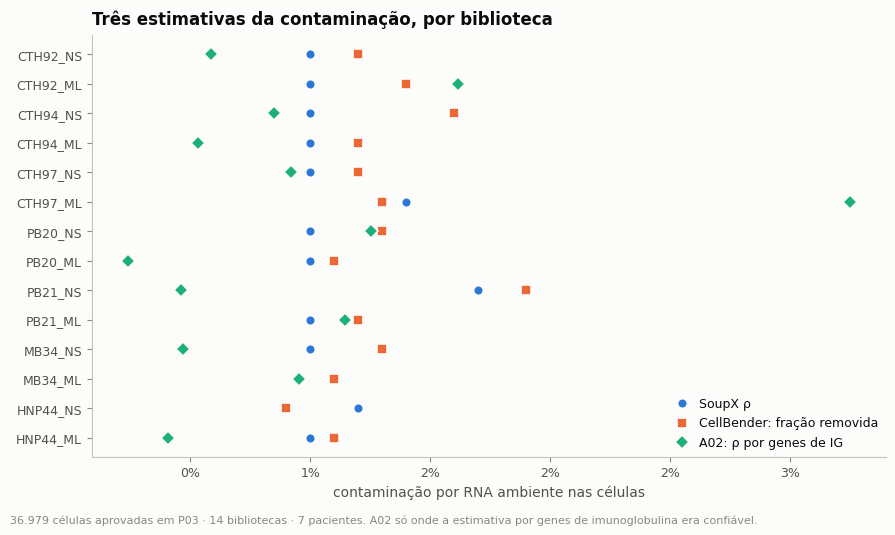

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.2))
y = np.arange(len(LIBS))[::-1]
marc = [("SoupX ρ", plotting.CATEGORICAL[0], "o"), ("CellBender: fração removida", plotting.CATEGORICAL[1], "s"),
        ("A02: ρ por genes de IG", plotting.CATEGORICAL[2], "D")]
for nome, cor, mk in marc:
    ax.plot(amb[nome].to_numpy(dtype=float) * 100, y, ls="", marker=mk, ms=7, mfc=cor, mec=INK["surface"], mew=1.2,
            label=nome, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(LIBS)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.f(v, 0) + "%"))
ax.set_xlabel("contaminação por RNA ambiente nas células")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
ax.set_title("Três estimativas da contaminação, por biblioteca")
plotting.note(fig, f"{F.n(len(cel))} células aprovadas em P03 · {plotting.N_DESIGN}. A02 só onde a estimativa por genes de "
                   "imunoglobulina era confiável.", y=0.0)
fig.tight_layout()
plotting.savefig(fig, NB, "rna_ambiente", description="Contaminação por RNA ambiente: SoupX, CellBender e A02",
                 data=amb.reset_index(), data_index=False)
plt.show()

### Efeito da correção nas citocinas

In [6]:
Xraw = sp.vstack(raw_parts).tocsr()
Xcor = sp.vstack(corr_parts).tocsr()
idx = {g: i for i, g in enumerate(gene_names)}
cyt = [g for g in config.CYTOKINES if g in idx]
lib_arr = cel["library_id"].to_numpy()
linhas = []
for g in cyt:
    r = np.asarray(Xraw[:, idx[g]].todense()).ravel()
    c = np.asarray(Xcor[:, idx[g]].todense()).ravel()
    linhas.append({"citocina": g, "positivas_brutas": int((r > 0).sum()), "positivas_soupx": int((c > 0).sum()),
                   "positivas_brutas_CTH97_ML": int(((r > 0) & (lib_arr == "CTH97_ML")).sum()),
                   "positivas_soupx_CTH97_ML": int(((c > 0) & (lib_arr == "CTH97_ML")).sum()),
                   "umis_brutos": int(r.sum()), "umis_soupx": int(c.sum())})
cit = pd.DataFrame(linhas).set_index("citocina")
cit["fração de positivas mantida"] = cit["positivas_soupx"] / cit["positivas_brutas"].replace(0, np.nan)
io.save_table(cit, NB, "citocinas_soupx", description="Células positivas para citocinas antes e depois da correção do SoupX")
cit

,positivas_brutas,positivas_soupx,positivas_brutas_CTH97_ML,positivas_soupx_CTH97_ML,umis_brutos,umis_soupx,fração de positivas mantida
citocina,,,,,,,
IFNG,1094,1031,624,580,13580,13469,0.942413
TNF,2311,2273,325,321,3928,3876,0.983557
IL2,95,85,2,2,1171,1160,0.894737
IL4,98,98,11,11,111,111,1.000000
IL5,313,311,2,2,445,442,0.993610
IL9,142,127,137,122,2300,2280,0.894366
IL10,56,54,2,2,71,69,0.964286
IL13,70,69,21,20,270,269,0.985714
IL17A,82,81,68,67,742,740,0.987805


## 3. Doublets: scDblFinder

In [7]:
cel = cel.reset_index(drop=True)
cel["scdbl_score"] = dbl["score"].to_numpy()
cel["scdbl_doublet"] = (dbl["class"] == "doublet").to_numpy()
fd = io.load_data("A03_doublets_recuperacao", "flags_doublets")
f6 = io.data_path("A06_doublets_solo_cxds", "flags_solo_cxds", "parquet")
f6 = pd.read_parquet(f6)
outros = fd.merge(f6, on=["library_id", "barcode"], how="outer")
cel = cel.merge(outros[["library_id", "barcode", "duplo_TB", "com_B", "scrublet_calibrado", "solo_calibrado",
                        "cxds_calibrado", "consenso"]], on=["library_id", "barcode"], how="left")
n_lib = cel.groupby("library_id").size().reindex(LIBS)
esp = pd.Series({l: db.expected_doublet_rate_10x(int(n_lib[l])) for l in LIBS})
thr_cal = {l: db.threshold_by_expected_rate(cel.loc[cel["library_id"] == l, "scdbl_score"].to_numpy(float), esp[l]) for l in LIBS}
cel["scdbl_calibrado"] = cel["scdbl_score"] >= cel["library_id"].map(thr_cal)
cel["duplo_TB"] = cel["duplo_TB"].fillna(False).astype(bool)
cel["doublet_removido"] = cel["scdbl_calibrado"] | cel["duplo_TB"]
dtab = pd.DataFrame({
    "células": n_lib,
    "doublets scDblFinder": cel.groupby("library_id")["scdbl_doublet"].sum().reindex(LIBS),
    "fração": cel.groupby("library_id")["scdbl_doublet"].mean().reindex(LIBS),
    "taxa esperada 10x": esp,
    "removidos (calibrado + T+B)": cel.groupby("library_id")["doublet_removido"].sum().reindex(LIBS),
})
io.save_table(dtab, NB, "scdblfinder_por_biblioteca", description="Doublets do scDblFinder por biblioteca × taxa esperada")
m_tb = cel["duplo_TB"].fillna(False).astype(bool)
k_tb, n_tb = int(cel.loc[m_tb, "scdbl_doublet"].sum()), int(m_tb.sum())
conc = {}
for nome in ["scrublet_calibrado", "solo_calibrado", "cxds_calibrado", "consenso"]:
    m = cel[nome].notna()
    a_, b_ = cel.loc[m, "scdbl_doublet"].astype(bool), cel.loc[m, nome].astype(bool)
    conc[nome] = {"células comparadas": int(m.sum()), "Jaccard com scDblFinder": float((a_ & b_).sum() / max((a_ | b_).sum(), 1))}
conc = pd.DataFrame(conc).T
io.save_table(conc, NB, "scdblfinder_concordancia", description="Concordância do scDblFinder com Scrublet, Solo, cxds e o consenso de A06")
print(f"scDblFinder: {F.n(cel['scdbl_doublet'].sum())} doublets com o limiar padrão ({F.pct(cel['scdbl_doublet'].mean(), 1)}); "
      f"esperado pela taxa do 10x ~{F.n((esp * n_lib).sum())}; dos {n_tb} doublets T + B validados (A03) entre as células aprovadas, "
      f"pega {k_tb}. Removidos adiante (calibrado + T+B): {F.n(cel['doublet_removido'].sum())}")
display(conc.round(3))
dtab.round(4)

scDblFinder: 2.809 doublets com o limiar padrão (7,6%); esperado pela taxa do 10x ~1.678; dos 55 doublets T + B validados (A03) entre as células aprovadas, pega 17. Removidos adiante (calibrado + T+B): 1.732


,células comparadas,Jaccard com scDblFinder
scrublet_calibrado,34611.0,0.239
solo_calibrado,34611.0,0.356
cxds_calibrado,34611.0,0.341
consenso,34611.0,0.325


,células,doublets scDblFinder,fração,taxa esperada 10x,removidos (calibrado + T+B)
CTH92_NS,866,24,0.0277,0.0069,6
CTH92_ML,1592,56,0.0352,0.0127,23
CTH94_NS,5967,497,0.0833,0.0477,298
CTH94_ML,545,15,0.0275,0.0044,10
CTH97_NS,1566,62,0.0396,0.0125,21
CTH97_ML,4849,306,0.0631,0.0388,191
PB20_NS,636,18,0.0283,0.0051,10
PB20_ML,850,32,0.0376,0.0068,9
PB21_NS,3913,247,0.0631,0.0313,123
PB21_ML,10879,1329,0.1222,0.0870,950


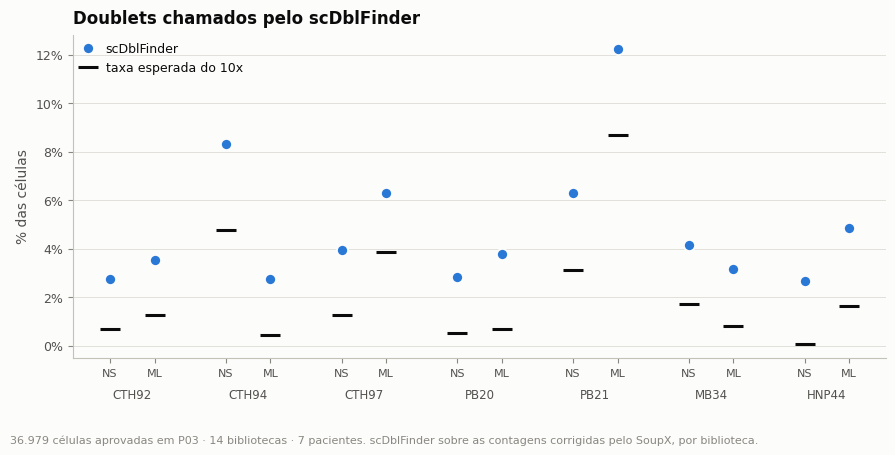

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.4))
pos = plotting.library_positions()
xs = np.array([pos[l] for l in LIBS])
ax.plot(xs, dtab["fração"] * 100, "o", ms=8, mfc=plotting.CATEGORICAL[0], mec=INK["surface"], mew=1.3, label="scDblFinder", zorder=3)
ax.plot(xs, dtab["taxa esperada 10x"] * 100, ls="", marker="_", ms=14, mew=2.2, color=INK["primary"], label="taxa esperada do 10x", zorder=2)
ax.set_xticks(xs)
ax.set_xticklabels([l.split("_")[1] for l in LIBS], fontsize=8)
for pat in config.PATIENTS:
    xm = np.mean([pos[f"{pat}_NS"], pos[f"{pat}_ML"]])
    ax.annotate(pat, (xm, 0), xycoords=("data", "axes fraction"), xytext=(0, -22), textcoords="offset points",
                ha="center", va="top", fontsize=8.5, color=INK["secondary"])
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.f(v, 0) + "%"))
ax.set_ylabel("% das células")
ax.set_title("Doublets chamados pelo scDblFinder")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plotting.note(fig, f"{F.n(len(cel))} células aprovadas em P03 · {plotting.N_DESIGN}. scDblFinder sobre as contagens corrigidas "
                   "pelo SoupX, por biblioteca.", y=0.0)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plotting.savefig(fig, NB, "scdblfinder", description="Fração de doublets do scDblFinder por biblioteca × taxa esperada",
                 data=dtab.reset_index(), data_index=False)
plt.show()

## 4. Objeto das células aprovadas

Contagens corrigidas pelo SoupX em `X`, brutas em `layers["counts_raw"]`,
com as métricas e as marcas de P01–P04 em `obs`. Fica no NVMe
(`HEAVY_OUT`); o objeto integrado de P05 é que vai para `dataReseq`.

In [9]:
obs = cel.drop(columns=[c for c in cel.columns if c.startswith(("lit_", "ref_"))]).copy()
obs.index = obs["cell_key"].to_numpy()
var = pd.DataFrame({"gene_ids": gene_ids, "gene_symbol": gene_names}, index=gene_ids)
for c in obs.columns:
    if obs[c].dtype == object:
        obs[c] = obs[c].astype(str)
adata = ad.AnnData(X=Xcor, obs=obs, var=var, layers={"counts_raw": Xraw})
adata.uns["soupx_rho"] = {k: (float(v) if pd.notna(v) else -1.0) for k, v in amb["SoupX ρ"].items()}
caminho = HEAVY / "celulas_aprovadas.h5ad"
io._assert_writable(caminho)
adata.write_h5ad(caminho, compression="gzip")
io.register(stage=NB, name="celulas_aprovadas", kind="h5ad", path=caminho,
            description="Células aprovadas em P03 com contagens SoupX (X) e brutas (layers['counts_raw'])", shape=adata.shape)
print(f"gravado: {caminho} ({caminho.stat().st_size / 1e6:.0f} MB); {adata.shape}")

gravado: /home/pedrovp/singleCellTaru_claude/reseq_raw/P04_ambiente_e_doublets/celulas_aprovadas.h5ad (491 MB); (36979, 38606)


## Problemas encontrados

In [10]:
issues = log.save()
print(log.summary().to_string())
show(issues)

severity
CRITICAL    0
MAJOR       0
MINOR       0
INFO        0


severity,location,problem,evidence,impact,recommendation


## Conclusão

**RNA ambiente.** O SoupX fica no piso da busca (ρ = 1%) na maioria das
bibliotecas — a contaminação real é ≤ 1%, como estimado em A02 e pelo
CellBender (0,9–1,9%). A correção tira sobretudo eventos de 1 UMI de
citocina em CTH97_ML (IL17F e IL22 mantêm ~86% das positivas; as demais,
89–100%).

**Doublets.** Com o limiar padrão, o scDblFinder marca 7,6% das células,
contra ~4,5% esperados pela taxa do 10x, e concorda pouco com Scrublet, Solo
e cxds (Jaccard 0,24–0,36). São removidos 1.732: o scDblFinder com limiar
calibrado pela taxa do 10x, por biblioteca, mais os doublets T + B
validados. PB21_ML, a biblioteca mais carregada, perde 950.

In [11]:
feitos = io.manifest()
feitos = feitos[feitos["stage"] == NB][["name", "kind"]].drop_duplicates(keep="last")
print(f"{len(feitos)} artefatos gravados por este notebook:")
print(feitos.to_string(index=False))

10 artefatos gravados por este notebook:
                      name   kind
              rna_ambiente  table
          fig_rna_ambiente figure
          fig_rna_ambiente  table
           citocinas_soupx  table
scdblfinder_por_biblioteca  table
  scdblfinder_concordancia  table
           fig_scdblfinder figure
           fig_scdblfinder  table
         celulas_aprovadas   h5ad
                    issues  table
